# Read file

In [16]:
import gzip
import numpy as np
import matplotlib.pyplot as plt

In [17]:
image_file = "/Users/kellyt/Documents/ml/HW8/MNISTdata/train-images-idx3-ubyte.gz"
label_file = "/Users/kellyt/Documents/ml/HW8/MNISTdata/train-labels-idx1-ubyte.gz"

with gzip.open(image_file, 'rb') as f:
    images = np.frombuffer(f.read(), dtype=np.uint8, offset=16)

with gzip.open(label_file, 'rb') as f:
    labels = np.frombuffer(f.read(), dtype=np.uint8, offset=8)

In [18]:
import gzip
import struct

with gzip.open(image_file, 'rb') as f:
    magic, num_images, rows, cols = struct.unpack(
        '>IIII', f.read(16)
    )

print("Magic number:", magic)
print("Number of images:", num_images)
print("Number of rows:", rows)
print("Number of columns:", cols)

Magic number: 2051
Number of images: 60000
Number of rows: 28
Number of columns: 28


In [19]:
images

array([0, 0, 0, ..., 0, 0, 0], dtype=uint8)

In [20]:
labels

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

In [21]:
images = images.reshape(-1, 28, 28) #28x28 is the original format

print(images.shape)
print(labels.shape)

(60000, 28, 28)
(60000,)


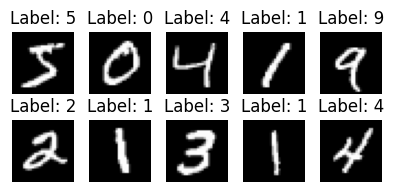

In [22]:
plt.figure(figsize=(4, 2))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(f"Label: {labels[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Data Preparation

In [23]:
# Flatten image
X = images.reshape(images.shape[0], -1)
y = labels

print(X.shape) # 784 cuz 28x28
print(y.shape)

(60000, 784)
(60000,)


In [24]:
X = X.astype('float32') / 255.0 # pixel values range from 0 to 255
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

# PCA

In [25]:
from sklearn.decomposition import PCA

In [26]:
pca = PCA(n_components=2) #reduce 784 features to 2 new features

X_pca = pca.fit_transform(X)
print(X_pca.shape)

(60000, 2)


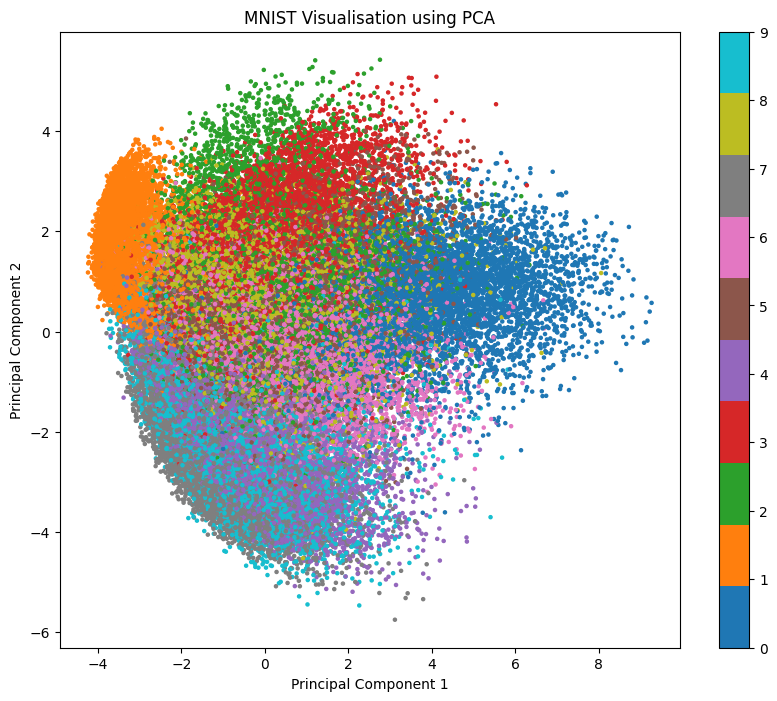

In [27]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='tab10',
    s=5
)

plt.colorbar(scatter, ticks=range(10))
plt.title('MNIST Visualisation using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

## Parameter config

In [28]:
# Use 5000 images for experimentation
X_sample = X[:5000]
y_sample = y[:5000]

# Reduce 784 dimensions to 50 using PCA
pca_50 = PCA(n_components=50)
X_50 = pca_50.fit_transform(X_sample)

print(X_50.shape)

(5000, 50)


In [29]:
for n in [2, 5, 10, 20, 50, 100]:
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X_sample)

    print(
        f"Components: {n}, "
        f"Explained variance: "
        f"{sum(pca.explained_variance_ratio_):.4f}"
    )

Components: 2, Explained variance: 0.1727
Components: 5, Explained variance: 0.3354
Components: 10, Explained variance: 0.4935
Components: 20, Explained variance: 0.6498
Components: 50, Explained variance: 0.8291
Components: 100, Explained variance: 0.9177


# t-SNE

In [30]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    max_iter=1000,
    random_state=42,
    init='pca'
)

X_tsne = tsne.fit_transform(X_50)

In [31]:
X_tsne

array([[ 18.095398,   8.354902],
       [ 58.458202,  27.36279 ],
       [ 25.112879, -44.347107],
       ...,
       [-16.86941 ,  47.936577],
       [-49.633965,  15.410599],
       [-19.844183,  42.928707]], dtype=float32)

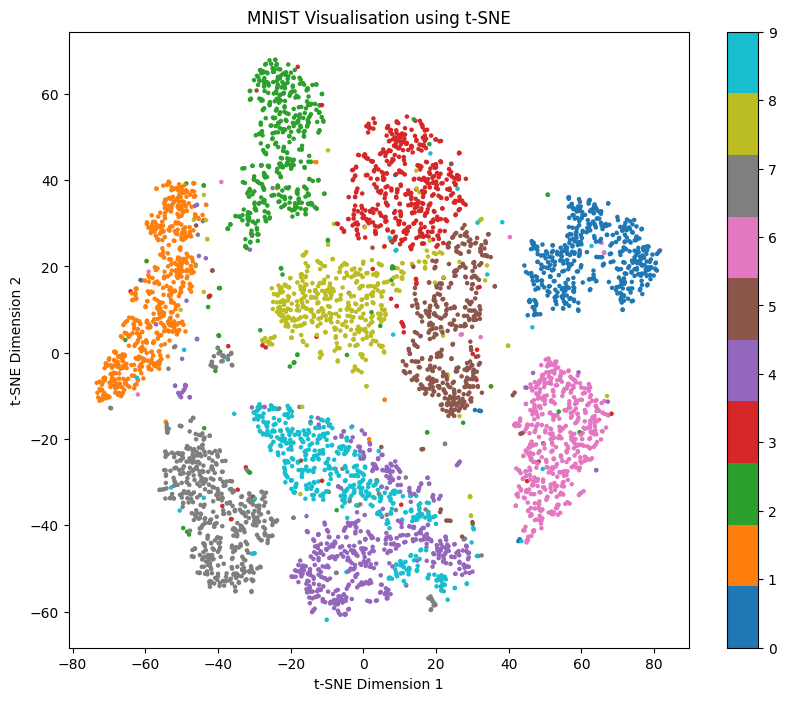

In [32]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y_sample,
    cmap='tab10',
    s=5
)

plt.colorbar(scatter, ticks=range(10))
plt.title('MNIST Visualisation using t-SNE')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.show()

## Parameter config: preplexity

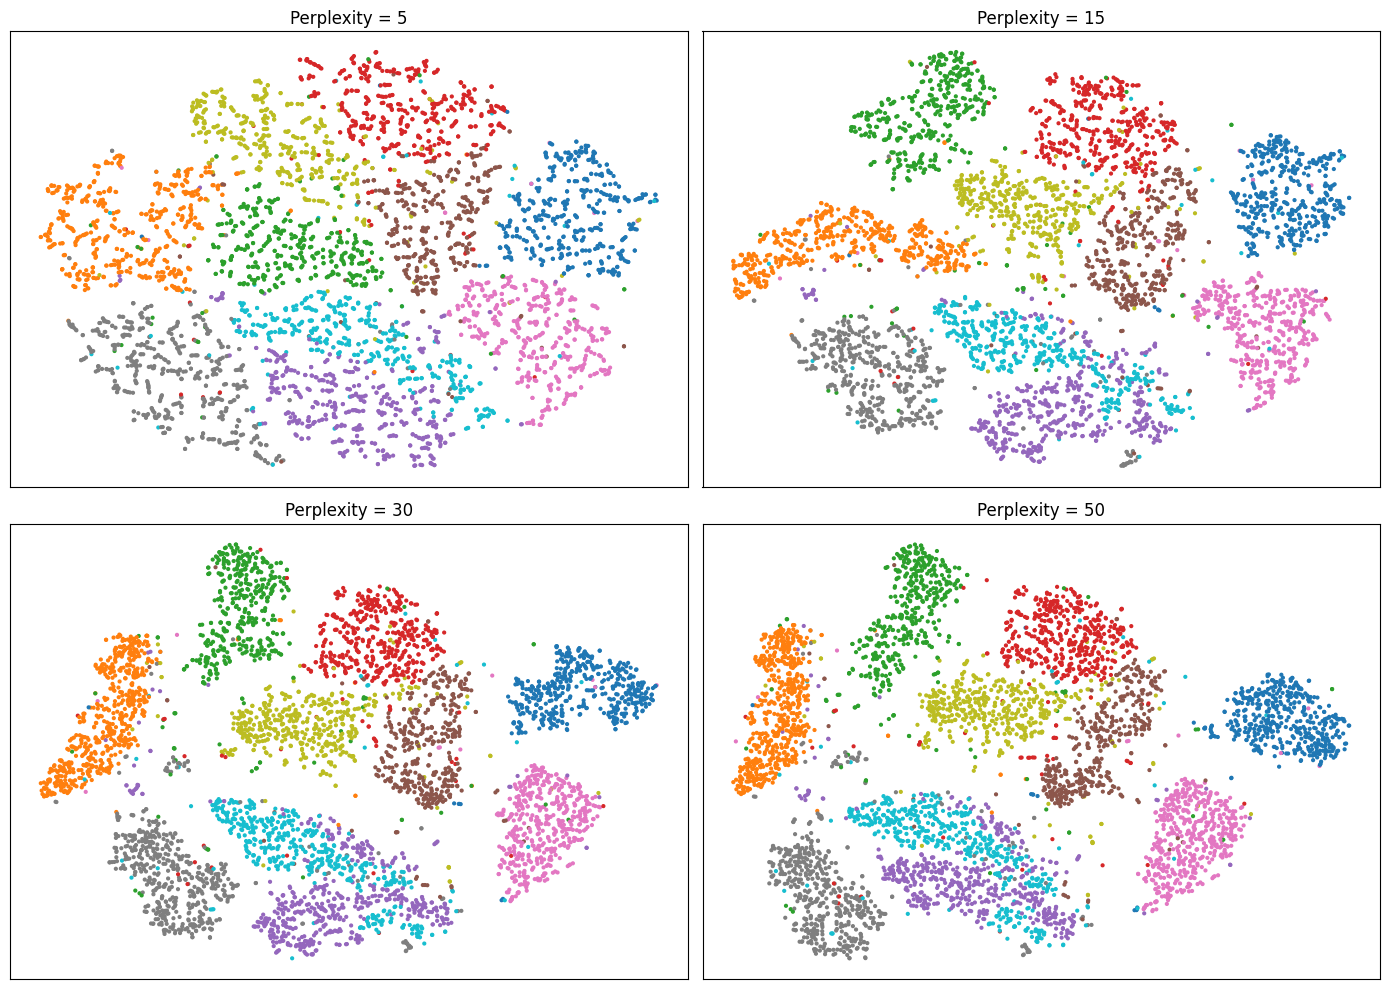

In [33]:
perplexities = [5, 15, 30, 50]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, p in zip(axes.ravel(), perplexities):

    tsne = TSNE(
        n_components=2,
        perplexity=p,
        learning_rate='auto',
        max_iter=1000,
        init='pca',
        random_state=42
    )

    X_embedded = tsne.fit_transform(X_50)

    ax.scatter(
        X_embedded[:, 0],
        X_embedded[:, 1],
        c=y_sample,
        cmap='tab10',
        s=4
    )

    ax.set_title(f'Perplexity = {p}')
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

# UMAP

In [34]:
# %pip install --force-reinstall "numpy==1.26.4" "numba==0.59.1" "llvmlite==0.42.0" "pynndescent==0.5.12"

In [35]:
import umap

/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [36]:
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric='euclidean',
    random_state=42
)

X_umap = umap_model.fit_transform(X_sample)

/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


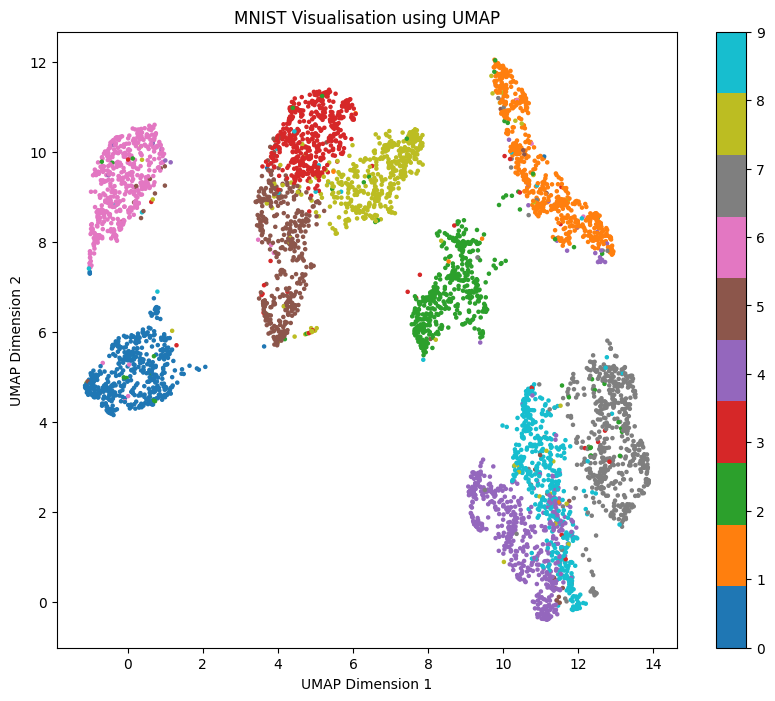

In [37]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=y_sample,
    cmap='tab10',
    s=5
)

plt.colorbar(scatter, ticks=range(10))
plt.title('MNIST Visualisation using UMAP')
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.show()

## Parameter config: n_neighbours rate

/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


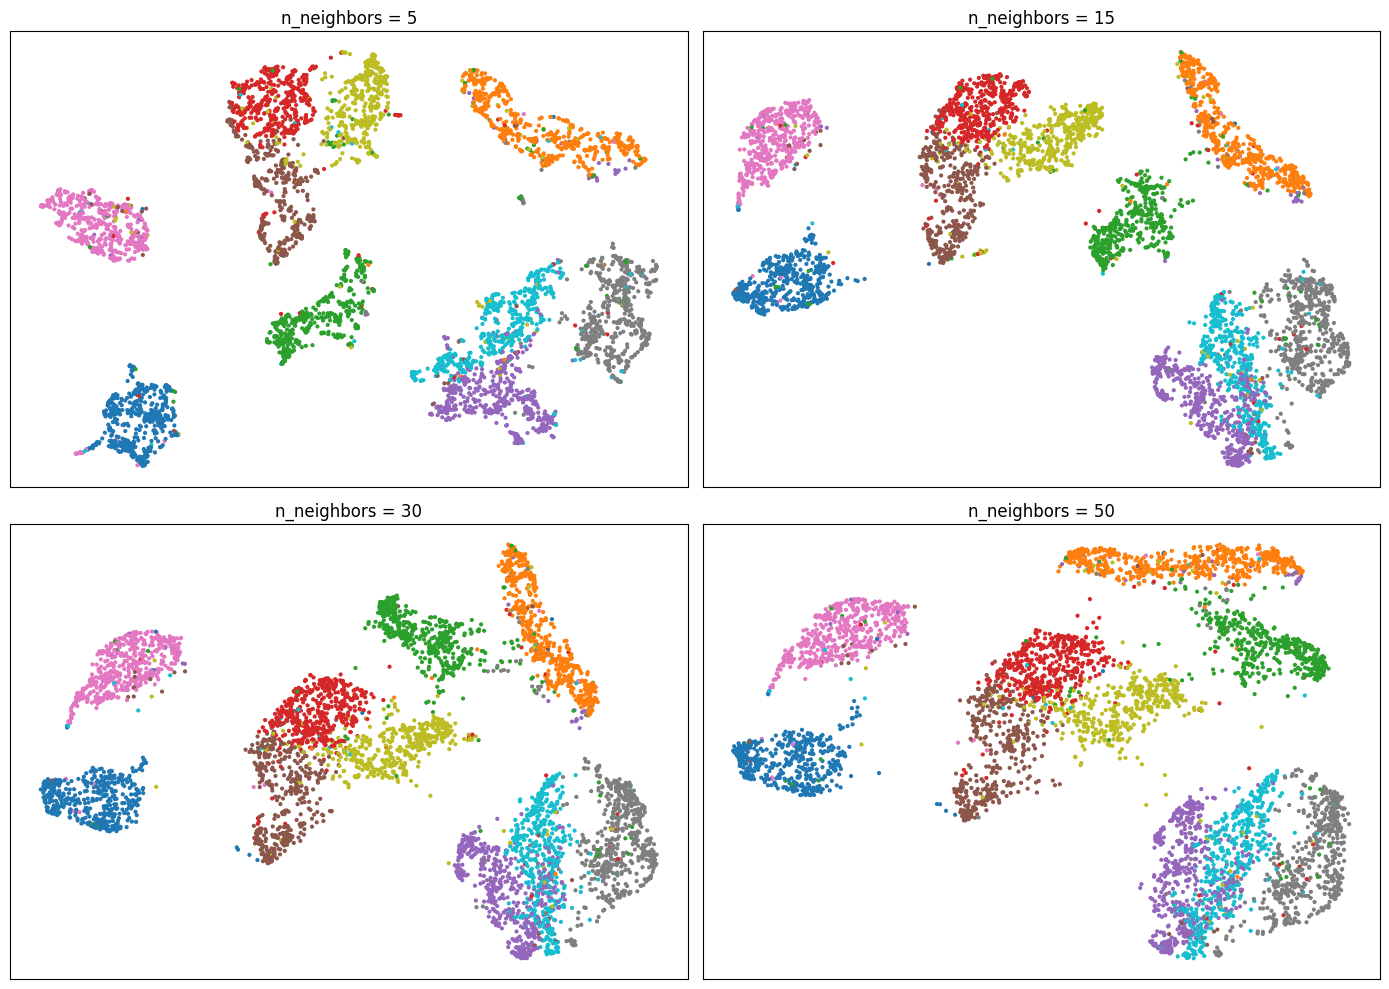

In [38]:
neighbors = [5, 15, 30, 50]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, n in zip(axes.ravel(), neighbors):

    model = umap.UMAP(
        n_components=2,
        n_neighbors=n,
        min_dist=0.1,
        metric='euclidean',
        random_state=42
    )

    X_embedded = model.fit_transform(X_sample)

    ax.scatter(
        X_embedded[:, 0],
        X_embedded[:, 1],
        c=y_sample,
        cmap='tab10',
        s=4
    )

    ax.set_title(f'n_neighbors = {n}')
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

## Parameter config: min_dist rate

/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


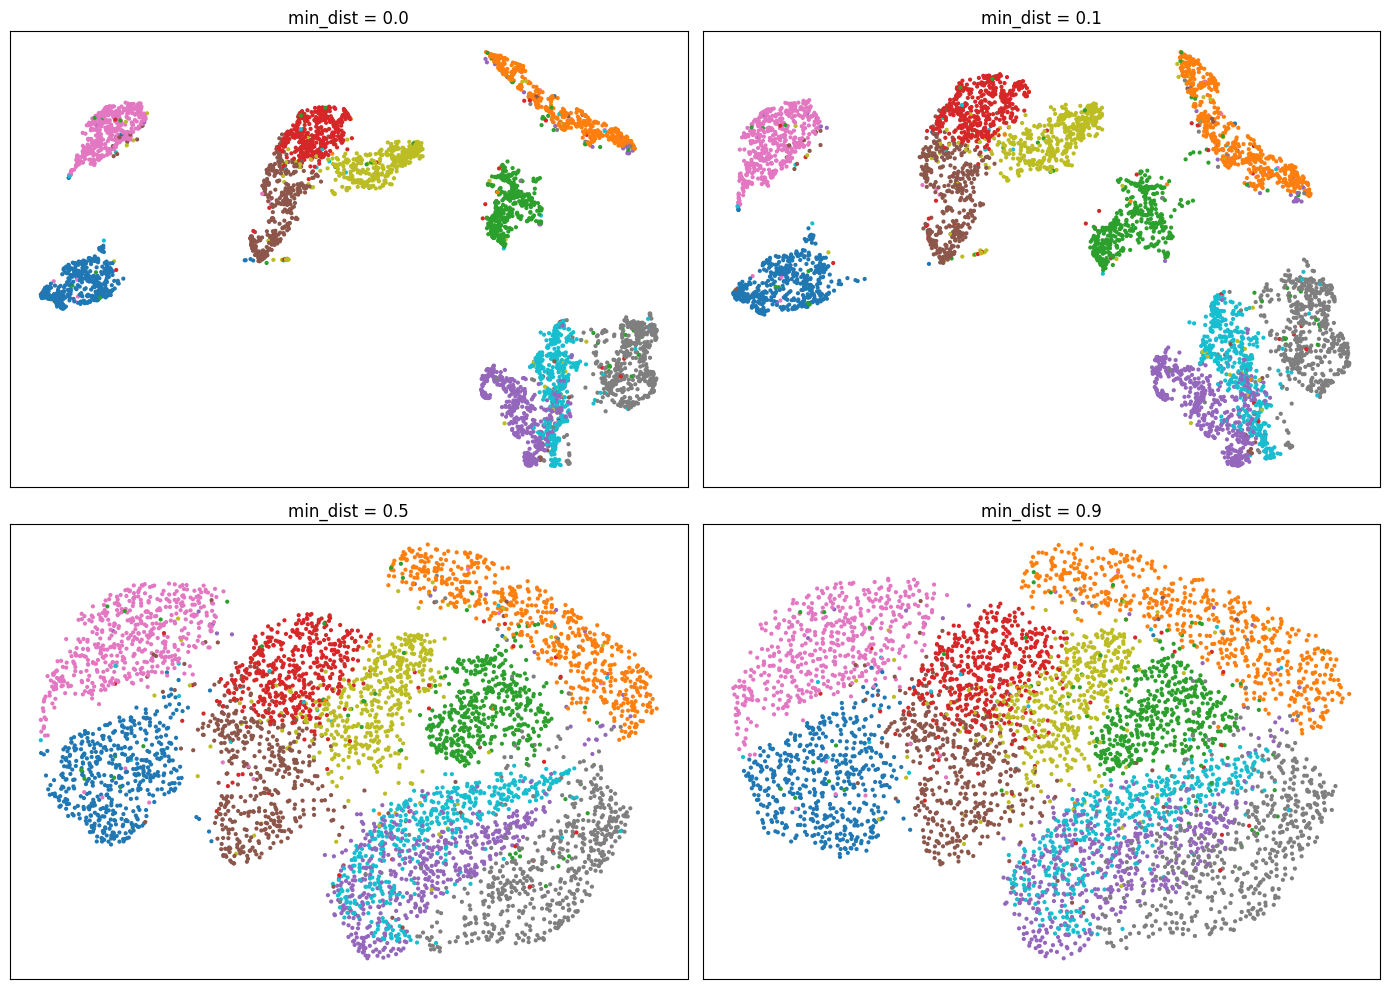

In [39]:
distances = [0.0, 0.1, 0.5, 0.9]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, d in zip(axes.ravel(), distances):

    model = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=d,
        random_state=42
    )

    X_embedded = model.fit_transform(X_sample)

    ax.scatter(
        X_embedded[:, 0],
        X_embedded[:, 1],
        c=y_sample,
        cmap='tab10',
        s=4
    )

    ax.set_title(f'min_dist = {d}')
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()